<div style="background:linear-gradient(135deg,#042f2e 0%,#0f766e 55%,#2dd4bf 100%);border-radius:18px;padding:32px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#99f6e4;font-weight:700;text-transform:uppercase">Chapter 151 &middot; Tools &amp; Workflow &middot; Notebook 5 of 5</div>
  <div style="font-size:32px;font-weight:900;line-height:1.1;margin:10px 0 6px">Visualization with Matplotlib &amp; Seaborn</div>
  <div style="font-size:15px;color:#ccfbf1;max-width:760px;line-height:1.6">A number is an answer; a picture is an argument. matplotlib gives you total control over every mark on a figure, and seaborn wraps it in one-line statistical plots. Together they turn the tables from the last notebook into charts a reader can grasp at a glance.</div>
</div>

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":110,"axes.grid":True,"grid.alpha":0.25,"font.size":11})
TL, TL2, AM, RD = "#0f766e", "#2dd4bf", "#d97706", "#dc2626"
BASE = "https://raw.githubusercontent.com/johnfisher-ai/Statistics-Data-Science-AI-Visual-Book/main/data/"
fn = "python-for-data-analysis--store-orders.xlsx"
def load(sheet="Orders"):
    try: return pd.read_excel("../../data/" + fn, sheet_name=sheet)
    except FileNotFoundError: return pd.read_excel(BASE + fn, sheet_name=sheet)
import seaborn as sns
sns.set_theme(style="whitegrid")
orders = load(); products = load("Products")
m = orders.merge(products, on="product_id", how="left")
orders["order_date"] = pd.to_datetime(orders.order_date)

## DEMO 1 &middot; The anatomy of a matplotlib figure
Every matplotlib chart is a **figure** (the whole canvas) holding one or more **axes** (a single plot). You draw on an axis, then label it. Start with the monthly revenue trend as a line.

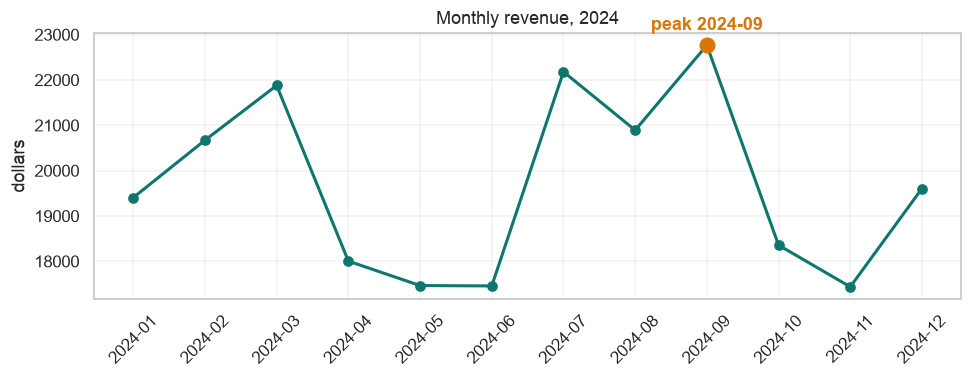

In [2]:
monthly = orders.groupby(orders.order_date.dt.to_period("M")).revenue.sum()
monthly.index = monthly.index.astype(str)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(monthly.index, monthly.values, marker="o", color=TL, lw=2)
peak = monthly.idxmax()
ax.scatter([peak], [monthly.max()], color=AM, zorder=5, s=90)
ax.annotate(f"peak {peak}", (peak, monthly.max()), textcoords="offset points", xytext=(0, 10), ha="center", color=AM, fontweight="bold")
ax.set_title("Monthly revenue, 2024"); ax.set_ylabel("dollars"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## DEMO 2 &middot; Bar charts for comparing categories
Bars compare a value across categories. A horizontal bar chart, sorted, is the clearest way to rank groups like revenue by region.

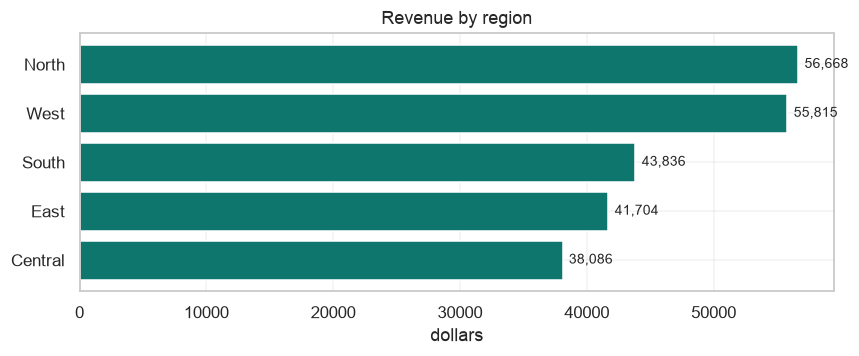

In [3]:
by_region = orders.groupby("region").revenue.sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(by_region.index, by_region.values, color=TL)
for i, v in enumerate(by_region.values):
    ax.text(v + 500, i, f"{v:,.0f}", va="center", fontsize=9)
ax.set_title("Revenue by region"); ax.set_xlabel("dollars")
plt.tight_layout(); plt.show()

## DEMO 3 &middot; Histograms for the shape of a distribution
A histogram bins one numeric column to show its shape. Order revenue is right-skewed: many small orders, a long tail of big ones, which the mean alone would hide.

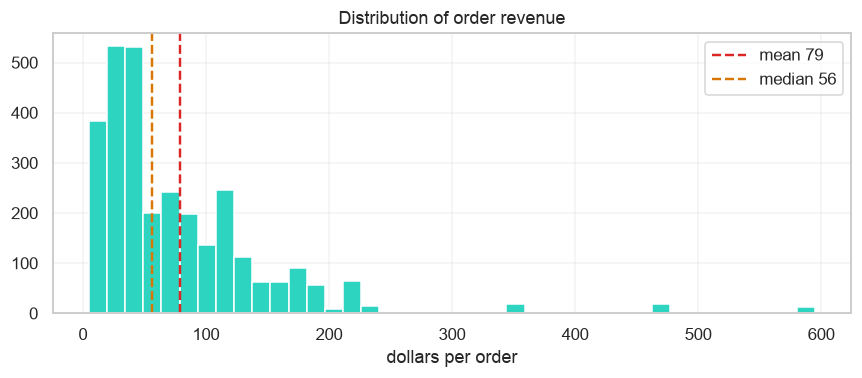

Right-skewed: the mean sits above the median, pulled up by the long tail of large orders.


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(orders.revenue, bins=40, color=TL2, edgecolor="white")
ax.axvline(orders.revenue.mean(), color=RD, ls="--", lw=1.6, label=f"mean {orders.revenue.mean():.0f}")
ax.axvline(orders.revenue.median(), color=AM, ls="--", lw=1.6, label=f"median {orders.revenue.median():.0f}")
ax.set_title("Distribution of order revenue"); ax.set_xlabel("dollars per order"); ax.legend()
plt.tight_layout(); plt.show()
print("Right-skewed: the mean sits above the median, pulled up by the long tail of large orders.")

## DEMO 4 &middot; Scatter plots for relationships
A scatter plot puts two numbers on the two axes to reveal how they relate. Color the points by a category to add a third dimension for free.

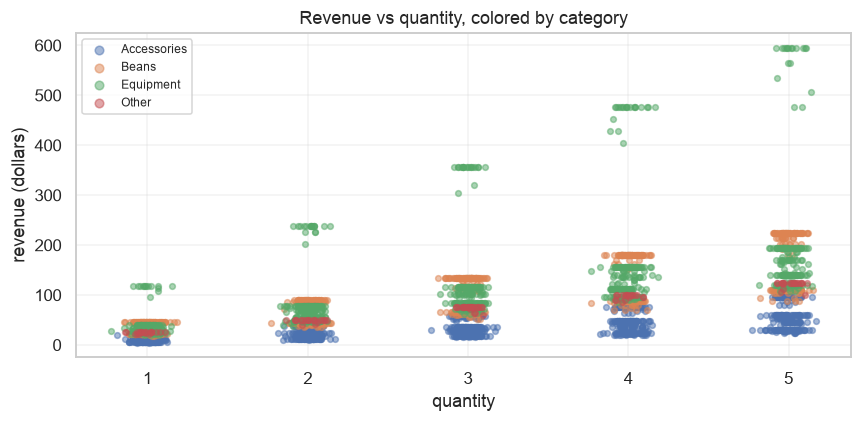

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for cat, sub in m.groupby("category"):
    ax.scatter(sub.quantity + np.random.default_rng(0).normal(0, 0.06, len(sub)), sub.revenue,
               s=14, alpha=0.5, label=cat)
ax.set_title("Revenue vs quantity, colored by category"); ax.set_xlabel("quantity"); ax.set_ylabel("revenue (dollars)")
ax.legend(fontsize=8, markerscale=1.5)
plt.tight_layout(); plt.show()

## DEMO 5 &middot; Seaborn: statistical plots in one line
seaborn works directly on a DataFrame and handles the grouping, error bars, and legend for you. A boxplot compares whole distributions across groups; a barplot shows group means with a confidence interval.

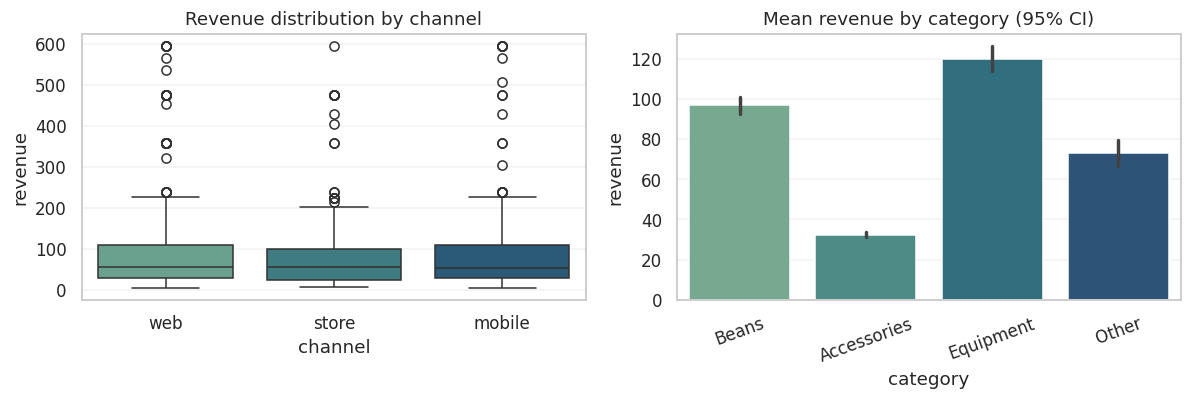

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=orders, x="channel", y="revenue", hue="channel", ax=ax[0], palette="crest", legend=False)
ax[0].set_title("Revenue distribution by channel")
sns.barplot(data=m, x="category", y="revenue", hue="category", ax=ax[1], palette="crest", legend=False, errorbar=("ci", 95))
ax[1].set_title("Mean revenue by category (95% CI)"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## DEMO 6 &middot; A small dashboard: several plots, one figure
Real reports combine views. Lay out a two-by-two grid of axes and fill each with a different angle on the same data, a compact dashboard from the pieces you have already built.

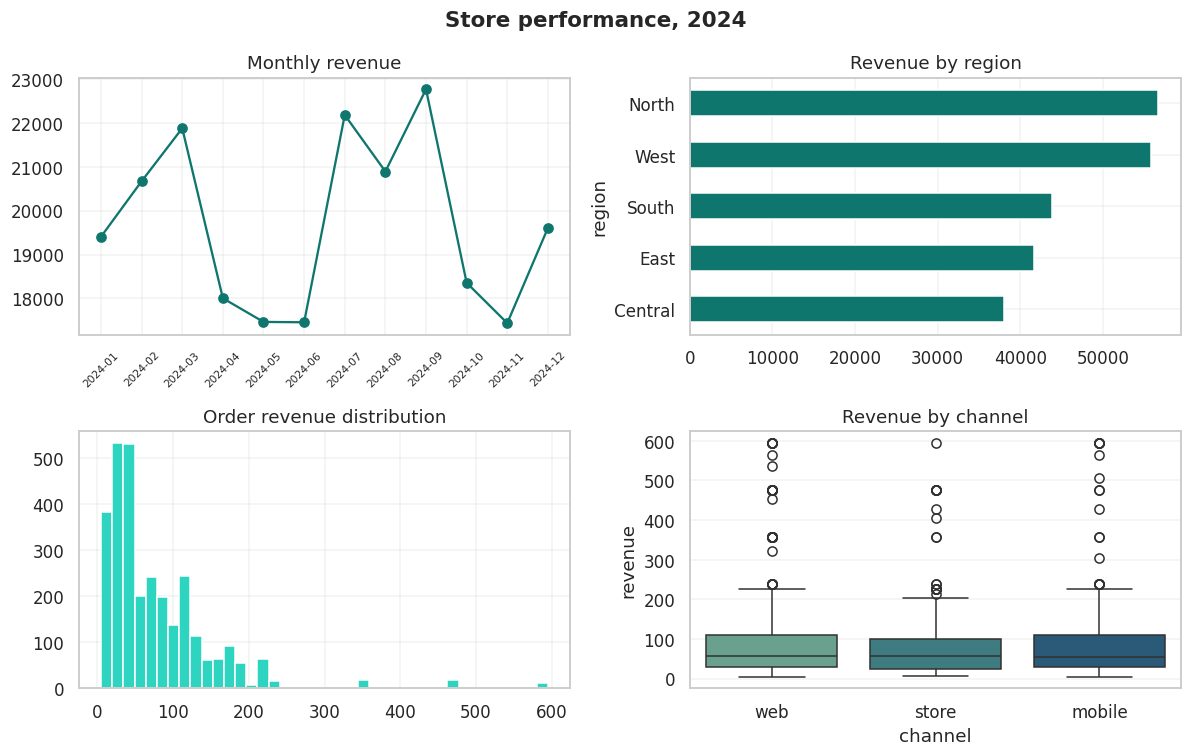

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
monthly = orders.groupby(orders.order_date.dt.to_period("M")).revenue.sum(); monthly.index = monthly.index.astype(str)
ax[0,0].plot(monthly.index, monthly.values, marker="o", color=TL); ax[0,0].set_title("Monthly revenue"); ax[0,0].tick_params(axis="x", rotation=45, labelsize=7)
orders.groupby("region").revenue.sum().sort_values().plot.barh(ax=ax[0,1], color=TL); ax[0,1].set_title("Revenue by region")
ax[1,0].hist(orders.revenue, bins=40, color=TL2, edgecolor="white"); ax[1,0].set_title("Order revenue distribution")
sns.boxplot(data=orders, x="channel", y="revenue", hue="channel", ax=ax[1,1], palette="crest", legend=False); ax[1,1].set_title("Revenue by channel")
fig.suptitle("Store performance, 2024", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### Wrap-up
matplotlib gave you the grammar (figure, axes, plot, label), and the standard chart types each answer a different question: a line for trend, bars for comparison, a histogram for shape, a scatter for relationship. seaborn added statistical plots in a single call, and subplots composed them into a dashboard. Five notebooks in, you can now take a raw file all the way to a chart, which is the entire arc of Python for data analysis.